# B1 plotting script: GFP mutant spectra

This notebook makes the figure for your report: the excitation (absorption) and emission spectra of wild-type GFP (wtGFP) above those of your mutant, so you can see how your mutation has shifted the peaks.

**How to use it:** run the cells in order from top to bottom by clicking in a cell and pressing **Shift + Enter**. Some cells you will need to edit. Lines starting with `#` are comments: notes for you to read, which Python ignores.

Author: Andrew Bowman. Revised 2026.

## 1. Import libraries
Libraries are ready-made toolkits. `pandas` reads data tables, `matplotlib` makes plots.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

## 2. Find your data files

You need two files from the plate reader: `Fluorescence.txt` (emission) and `Absorption.txt` (excitation).

Replace the text in quotes with the folder where your files are saved. On a Mac, right-click the folder, choose **Get Info**, copy the **Where** path, then add `/` and the folder's own name to the end. You should save the 'fluorescence.txt' and 'absorption.txt' files from the 96-well plate reader here. This is where I saved them on my Onedrive directory. Your will be different.

In [3]:
os.chdir("/Users/u5845279/Library/CloudStorage/OneDrive-UniversityofWarwick/files")

## 3. Read the data

The files are tab-separated (`sep="\t"`). The plate reader writes two lines of information above the column headings, so `skiprows=2` tells Python to skip them.

The second cell prints the column names and wells so you can check the files have been read correctly. You should see `Well` in both lists.

In [4]:
# 
# pd.read_csv reads a data file into a table (called a "DataFrame").
# "Fluorescence.txt"  the name of the file to read
# sep="\t"            the columns are separated by tabs ("\t" means tab)
# skiprows=2          skip the first two lines of instrument information (this are not needed)
# The table is stored in a variable (a named box), here Em or Ex,
# so we can use it later by writing its name.
Em = pd.read_csv("fluorescence.txt", sep="\t", skiprows=2)   # emission data
Ex = pd.read_csv("absorption.txt", sep="\t", skiprows=2)     # excitation (absorption) data

# The plate reader puts a space in front of each well name (" A03" instead of "A03").
# .str.strip() removes spaces from the start and end of each name, so that
# "A03" typed in step 4 matches the well names in the data.
Em["Well"] = Em["Well"].str.strip()
Ex["Well"] = Ex["Well"].str.strip()

In [5]:
# print() displays text and values below the cell.
# Em.columns is the list of column headings in the table.
# Em["Well"] picks out the "Well" column, and .unique() lists each
# well name once, so we can see which wells were measured.
# These should line up with the loading guide uploaded to the Teams folder.

print("Fluorescence columns:", list(Em.columns))
print("Absorption columns:", list(Ex.columns))
print("Wells on the plate:", list(Em["Well"].unique()))

Fluorescence columns: ['Plate', 'Well', 'Type', 'Group', 'Sample', 'Meas. time [s]', 'RFU', 'Em', 'Ex', 'Unnamed: 9']
Absorption columns: ['Plate', 'Well', 'Type', 'Group', 'Sample', 'Meas. time [s]', 'Abs', 'Wavelength', 'Unnamed: 8']
Wells on the plate: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'C01', 'C02', 'C03', 'C04']


In [6]:
# You could also check your data has been read in correctly by using the head() function. e.g
Em.head()

,Plate,Well,Type,Group,Sample,Meas. time [s],RFU,Em,Ex,Unnamed: 9
0,INS 24-25,A01,Unknown,Assay,Un_0001 1/1,0.00,0.105156,420,382,NaN
1,INS 24-25,A01,Unknown,Assay,Un_0001 1/1,0.13,0.143707,422,382,NaN
2,INS 24-25,A01,Unknown,Assay,Un_0001 1/1,0.27,0.190463,424,382,NaN
3,INS 24-25,A01,Unknown,Assay,Un_0001 1/1,0.40,0.167909,426,382,NaN
4,INS 24-25,A01,Unknown,Assay,Un_0001 1/1,0.54,0.214776,428,382,NaN


## 4. Choose your wells (need to edit)

Change `mywell` to the well containing your mutant, and `mutant_name` to the mutation you made. This is used to label your figure.

In [7]:
mywell = "A02"          # the well containing YOUR mutant
mutant_name = "Y66W"    # "Y66W" or "T203Y"

# Colours for your mutant's lines in the figure. It's cute if these are refelctive of your excitation and emission spectra.
# Python understands many colour names, e.g. "blue", "deepskyblue", "gold", "orange".
# If you made T203Y, which emits yellow light, try mutant_em_colour = "gold".
mutant_ex_colour = "blue"          # excitation (absorption) line
mutant_em_colour = "deepskyblue"   # emission line (light blue)

GFP_well = "C02"        # wild-type GFP (don't change)
GFP_name = "wtGFP"
npl_well = "C01"        # 'no plasmid' control, for background subtraction (don't change)

## 5. Functions

A **function** is a small reusable piece of code. You give it some inputs, it does a job, and it hands back a result. We define two here and use them below.

In [8]:
# A function starts with "def", then its name, then its inputs in brackets.
# The indented lines underneath are what it does.
# "return" hands the result back to wherever the function was used.

# get_well: pick out the rows of the data that belong to one well.
#   data["Well"] == well   checks every row: is this row's well the one we want?
#                          This gives True or False for each row.
#   data[ ... ]            keeps only the rows where the answer was True.
def get_well(data, well):
    return data[data["Well"] == well]


# normalise: rescale a spectrum so its lowest point is 0 and its highest is 1.
# Subtracting the minimum moves the lowest point to 0; dividing by the
# range (max - min) then makes the highest point exactly 1.
# This lets us compare the SHAPE of spectra that differ a lot in brightness.
def normalise(values):
    return (values - values.min()) / (values.max() - values.min())

## 6. Extract and normalise the spectra

This pulls out the excitation and emission spectra for wild-type GFP and your mutant, and normalises them.

In [9]:
# Each line uses a function from step 5 and stores the result in a new variable.
# ["Abs"] and ["RFU"] pick out the column of measurements to normalise:
#   "Abs" = absorbance (excitation file), "RFU" = relative fluorescence units (emission file)

# Wild-type GFP
GFP_ex = get_well(Ex, GFP_well)
GFP_em = get_well(Em, GFP_well)
GFP_ex_norm = normalise(GFP_ex["Abs"])
GFP_em_norm = normalise(GFP_em["RFU"])

# Your mutant
my_ex = get_well(Ex, mywell)
my_em = get_well(Em, mywell)
my_ex_norm = normalise(my_ex["Abs"])
my_em_norm = normalise(my_em["RFU"])

### Background subtraction

If your mutant is only weakly fluorescent, its emission may look like a curve falling from left to right with no clear peak. That curve is mostly background from the cells themselves. Running this cell subtracts the 'no plasmid' control (cells without GFP - labelled 'BL21' in the picture of the loading map) from your raw readings, then normalises again, which often reveals the real peak.

This is most important for the Y66W mutant, which is a lot dimmer than the T203Y mutant.

In [10]:
# Get the 'no plasmid' control spectra
npl_ex = get_well(Ex, npl_well)
npl_em = get_well(Em, npl_well)

# Subtract the control's RAW readings from your mutant's RAW readings,
# point by point, THEN normalise. This replaces the normalised spectra
# from step 6. (.values tells Python to subtract the numbers in order,
# first from first, second from second, and so on.)
my_ex_norm = normalise(my_ex["Abs"] - npl_ex["Abs"].values)
my_em_norm = normalise(my_em["RFU"] - npl_em["RFU"].values)

## 7. Plot the spectra

Now we make two separate plots: one for wtGFP and one for your mutant. Each plot shows the excitation and emission spectra.

Both plots use the same wavelength range, so if you place one above the other (e.g. in PowerPoint), you can compare the positions of the peaks and see how far your mutation has shifted them.

Each plot is also saved as an image file (`wtGFP_spectra.png` and `mutant_spectra.png`) in the same folder as your data, ready for your report.

### Plot 1: wtGFP

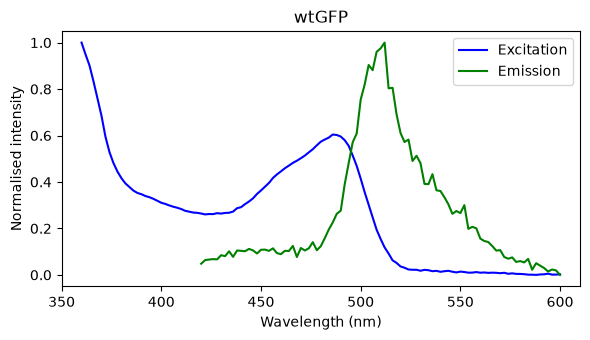

In [12]:
# plt.figure() starts a new, empty plot.
# figsize=(6, 3.5) sets its size: 6 inches wide and 3.5 inches tall.
plt.figure(figsize=(6, 3.5))

# plt.plot(x, y) draws a line through the points.
#   x = the wavelengths ("Wavelength" column for excitation, "Em" column for emission)
#   y = the normalised intensities we calculated in step 6
#   color = the colour of the line
#   label = the name shown for this line in the legend (key)
plt.plot(GFP_ex["Wavelength"], GFP_ex_norm, color="blue", label="Excitation")
plt.plot(GFP_em["Em"], GFP_em_norm, color="green", label="Emission")

# plt.xlim sets the range of the wavelength axis (from 350 to 610 nm).
# We use the same range for both plots so they line up when placed one above the other.
plt.xlim(350, 610)

# Add a title, axis labels and a legend (the legend uses the label= text from plt.plot)
plt.title(GFP_name)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Normalised intensity")
plt.legend()

# tight_layout() stops the labels being cut off at the edges.
# savefig saves the plot as an image file; dpi=300 makes it sharp enough for a report.
# show() displays the plot below this cell.
plt.tight_layout()
plt.savefig("wtGFP_spectra.png", dpi=300)
plt.show()

### Plot 2: your mutant

This is exactly the same code as Plot 1, but using your mutant's data, name and colours (from step 4).

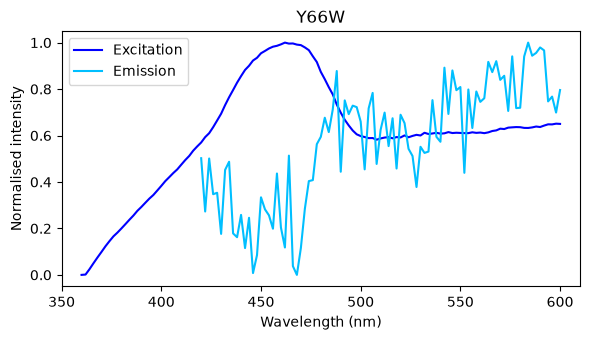

In [13]:
# Start a new, empty plot (same size as Plot 1)
plt.figure(figsize=(6, 3.5))

# Draw your mutant's excitation and emission spectra
plt.plot(my_ex["Wavelength"], my_ex_norm, color=mutant_ex_colour, label="Excitation")
plt.plot(my_em["Em"], my_em_norm, color=mutant_em_colour, label="Emission")

# Same wavelength range as Plot 1, so the two plots line up
plt.xlim(350, 610)

# Title, axis labels and legend
plt.title(mutant_name)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Normalised intensity")
plt.legend()

# Tidy, save and show
plt.tight_layout()
plt.savefig("mutant_spectra.png", dpi=300)
plt.show()

### Comparison plots

These two plots put your mutant and wtGFP on the same axes: first the excitation spectra, then the emission spectra. This makes it easy to see which way, and roughly how far, each spectrum has shifted.

wtGFP is drawn as a black dashed line and your mutant in its own colour, so you can tell them apart.

The plots are saved as `excitation_comparison.png` and `emission_comparison.png`.

### Plot 3: excitation, your mutant vs wtGFP

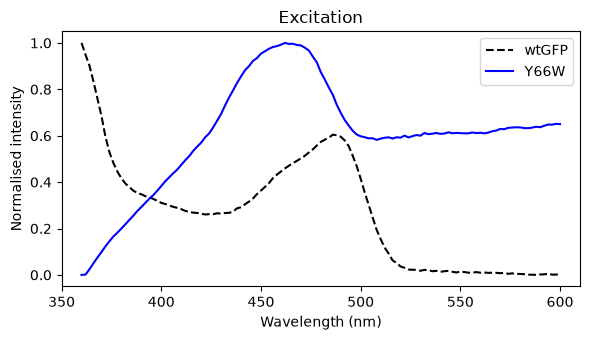

In [14]:
# Start a new, empty plot (same size as the others)
plt.figure(figsize=(6, 3.5))

# This time we draw two EXCITATION spectra on the same plot:
#   wtGFP in black, with linestyle="--" to make it dashed
#   your mutant in the excitation colour you chose in step 4
# The label= text uses the names from step 4, so the legend shows which is which.
plt.plot(GFP_ex["Wavelength"], GFP_ex_norm, color="black", linestyle="--", label=GFP_name)
plt.plot(my_ex["Wavelength"], my_ex_norm, color=mutant_ex_colour, label=mutant_name)

# Same wavelength range as the other plots
plt.xlim(350, 610)

# Title, axis labels and legend
plt.title("Excitation")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Normalised intensity")
plt.legend()

# Tidy, save and show
plt.tight_layout()
plt.savefig("excitation_comparison.png", dpi=300)
plt.show()

### Plot 4: emission, your mutant vs wtGFP

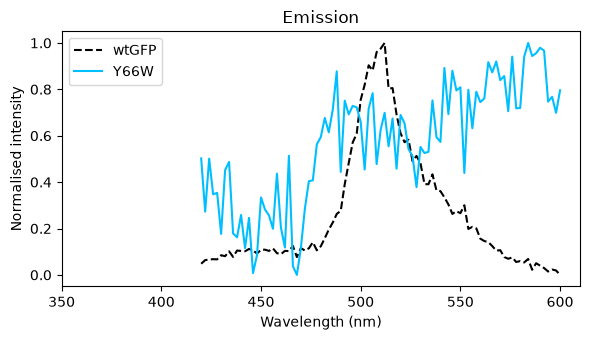

In [15]:
# Exactly the same as Plot 3, but using the EMISSION data
# (the "Em" column for wavelengths, and the normalised emission intensities)
plt.figure(figsize=(6, 3.5))

plt.plot(GFP_em["Em"], GFP_em_norm, color="black", linestyle="--", label=GFP_name)
plt.plot(my_em["Em"], my_em_norm, color=mutant_em_colour, label=mutant_name)

plt.xlim(350, 610)

plt.title("Emission")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Normalised intensity")
plt.legend()

plt.tight_layout()
plt.savefig("emission_comparison.png", dpi=300)
plt.show()

## 8. In your report

In your figure legend, give the approximate excitation and emission peak wavelengths for wild-type GFP and your mutant (read them from your plots), and how far each has shifted. Say whether you used background subtraction.